Project outline:
1. Data audit + imbalance
2. Clean pipeline (no leakage): preprocess -> model
3. Baseline CV + Light tuning (LR / RF / optional XGB)
4. VotingSoft ensemble (built BEFORE model selection)
5. Repeated Stratified CV (5-fold x 5 repeats) for stability
6. Final model selection (CV evidence)
7. Test evaluation: metrics + confusion matrix + ROC + PR + threshold table + calibration
8. SHAP global + local explanations (final or SHAP-friendly base if VotingSoft wins)
9. Decision-support prototype table from SHAP (Top-N high risk)

In [18]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
    cross_validate, RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

# XGBoost
try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception:
    XGB_AVAILABLE = False
    print("xgboost not found. XGBoost will be skipped.")

# SHAP
try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False
    print("shap not found. SHAP sections will be skipped.")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load data

Shape: (303, 14)
Missing total: 0 | Duplicates: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0



Class distribution (0=no disease, 1=disease):


target
0    164
1    139
Name: count, dtype: int64

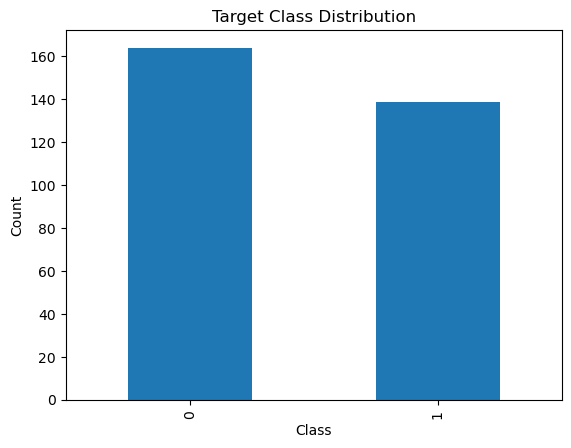

In [20]:
# 1) Load data + audit
# -----------------------------
DATA_PATH = "Heart_disease_cleveland_new.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Cannot find {DATA_PATH}. Put it next to the notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)

# Detect target
target_col = "target" if "target" in df.columns else df.columns[-1]
df[target_col] = (df[target_col].astype(float) > 0).astype(int)
assert set(df[target_col].unique()).issubset({0, 1}), "Target must be binary 0/1."

print("Shape:", df.shape)
print("Missing total:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
display(df.head())

# Class distribution
class_counts = df[target_col].value_counts().sort_index()
print("\nClass distribution (0=no disease, 1=disease):")
display(class_counts)

plt.figure()
class_counts.plot(kind="bar")
plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()


In [21]:
# 2) X, y + feature typing
# -----------------------------
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
object_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

# treat low-cardinality ints as categorical (heuristic)
cat_like_ints = [c for c in numeric_cols if X[c].nunique(dropna=True) <= 10]
categorical_features = sorted(list(set(object_cols + cat_like_ints)))
numeric_features = [c for c in numeric_cols if c not in categorical_features]

# -----------------------------
# 3) Light feature engineering (optional, minimal)
# -----------------------------
def safe_div(a, b, eps=1e-9):
    return a / (b + eps)

engineered = []
if "chol" in X.columns and "age" in X.columns:
    X["chol_per_age"] = safe_div(X["chol"].astype(float), X["age"].astype(float))
    engineered.append("chol_per_age")

if "trestbps" in X.columns and "age" in X.columns:
    X["bps_per_age"] = safe_div(X["trestbps"].astype(float), X["age"].astype(float))
    engineered.append("bps_per_age")

if engineered:
    print("\nEngineered features added:", engineered)

# Recompute typing after engineering
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
object_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
cat_like_ints = [c for c in numeric_cols if X[c].nunique(dropna=True) <= 10 and c not in engineered]
categorical_features = sorted(list(set(object_cols + cat_like_ints)))
numeric_features = [c for c in numeric_cols if c not in categorical_features]

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)



Engineered features added: ['chol_per_age', 'bps_per_age']

Numeric features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'chol_per_age', 'bps_per_age']
Categorical features: ['ca', 'cp', 'exang', 'fbs', 'restecg', 'sex', 'slope', 'thal']


In [22]:
# 4) Train/test split (holdout)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("\nTrain size:", X_train.shape, "| Test size:", X_test.shape)

# -----------------------------
# 5) Preprocess pipeline (NO leakage)
# -----------------------------
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, numeric_features),
    ("cat", cat_pipe, categorical_features)
])


Train size: (242, 15) | Test size: (61, 15)


In [23]:
# 6) Models (balanced)
# -----------------------------
pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

lr = LogisticRegression(max_iter=800, class_weight="balanced", random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE)

models = {
    "LogisticRegression": lr,
    "RandomForest": rf
}

if XGB_AVAILABLE:
    xgb = XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=3,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=RANDOM_STATE, eval_metric="logloss",
        scale_pos_weight=scale_pos_weight
    )
    models["XGBoost"] = xgb

pipelines = {k: Pipeline([("preprocess", preprocess), ("model", v)]) for k, v in models.items()}


In [24]:
# 7) CV utilities
# -----------------------------
scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "accuracy": "accuracy"
}

def cv_table(pipes, X_, y_, cv_obj):
    rows = []
    for name, pipe in pipes.items():
        out = cross_validate(pipe, X_, y_, cv=cv_obj, scoring=scoring, n_jobs=-1)
        row = {"Model": name}
        for m in scoring:
            row[f"{m}_mean"] = float(np.mean(out[f"test_{m}"]))
            row[f"{m}_std"]  = float(np.std(out[f"test_{m}"]))
        rows.append(row)
    return pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)

# -----------------------------
# 8) Baseline CV (5-fold)
# -----------------------------
cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Baseline CV (5-fold):")
cv_baseline = cv_table(pipelines, X_train, y_train, cv_5fold)
display(cv_baseline)

Baseline CV (5-fold):


,Model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std
0,LogisticRegression,0.899405,0.014020,0.832349,0.023200,0.867899,0.068228,0.809881,0.073823,0.851105,0.021189
1,RandomForest,0.889659,0.027391,0.782778,0.033609,0.801725,0.038393,0.773913,0.087517,0.805782,0.016529
2,XGBoost,0.846829,0.030361,0.765393,0.046715,0.761741,0.030695,0.774308,0.087131,0.785034,0.034227


In [25]:
# 9) Light tuning (kept small for runtime)
# -----------------------------
tuned = {}

# LR tuning
lr_search = RandomizedSearchCV(
    pipelines["LogisticRegression"],
    {"model__C": [0.1, 1, 10]},
    n_iter=3, scoring="roc_auc", cv=cv_5fold, random_state=RANDOM_STATE, n_jobs=-1
)
lr_search.fit(X_train, y_train)
tuned["LogisticRegression"] = lr_search.best_estimator_
print("Best LR params:", lr_search.best_params_)

# RF tuning
rf_search = RandomizedSearchCV(
    pipelines["RandomForest"],
    {"model__n_estimators": [200, 400],
     "model__max_depth": [None, 3, 5],
     "model__min_samples_leaf": [1, 3, 5]},
    n_iter=10, scoring="roc_auc", cv=cv_5fold, random_state=RANDOM_STATE, n_jobs=-1
)
rf_search.fit(X_train, y_train)
tuned["RandomForest"] = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)

# XGB tuning (optional)
if "XGBoost" in pipelines:
    xgb_search = RandomizedSearchCV(
        pipelines["XGBoost"],
        {"model__n_estimators": [200, 400],
         "model__max_depth": [2, 3, 4],
         "model__learning_rate": [0.05, 0.1],
         "model__subsample": [0.8, 1.0],
         "model__colsample_bytree": [0.8, 1.0]},
        n_iter=15, scoring="roc_auc", cv=cv_5fold, random_state=RANDOM_STATE, n_jobs=-1
    )
    xgb_search.fit(X_train, y_train)
    tuned["XGBoost"] = xgb_search.best_estimator_
    print("Best XGB params:", xgb_search.best_params_)

Best LR params: {'model__C': 0.1}
Best RF params: {'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_depth': 3}
Best XGB params: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


In [26]:
# 10) Build VotingSoft BEFORE selection
# -----------------------------
ens_estimators = []
if "LogisticRegression" in tuned: ens_estimators.append(("lr", tuned["LogisticRegression"]))
if "RandomForest" in tuned:       ens_estimators.append(("rf", tuned["RandomForest"]))
if "XGBoost" in tuned:            ens_estimators.append(("xgb", tuned["XGBoost"]))

if len(ens_estimators) >= 2:
    tuned["VotingSoft"] = VotingClassifier(estimators=ens_estimators, voting="soft")

print("Tuned CV (5-fold) incl. VotingSoft:")
cv_tuned_5fold = cv_table(tuned, X_train, y_train, cv_5fold)
display(cv_tuned_5fold)

# -----------------------------
# 11) Repeated Stratified CV (stability check)
#     5-fold x 5 repeats = 25 runs
# -----------------------------
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
print("Repeated Stratified CV (5x5) incl. VotingSoft:")
cv_tuned_repeated = cv_table(tuned, X_train, y_train, rskf)
display(cv_tuned_repeated)

# Tip: For “stability”, look at roc_auc_std (lower = more stable)

# -----------------------------
# 12) Select final model (LOGIC: choose by repeated CV AUC)
# -----------------------------
best_model_name = cv_tuned_repeated.iloc[0]["Model"]
final_model = tuned[best_model_name]
print("Final selected model (by repeated CV AUC):", best_model_name)

Tuned CV (5-fold) incl. VotingSoft:


,Model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std
0,LogisticRegression,0.903114,0.017300,0.813175,0.023009,0.823221,0.043486,0.809881,0.067996,0.830442,0.016761
1,RandomForest,0.899906,0.023297,0.779255,0.034943,0.794466,0.045776,0.773518,0.087499,0.801446,0.022782
3,VotingSoft,0.895929,0.018541,0.788176,0.051722,0.802529,0.056096,0.782609,0.093802,0.809609,0.041339
2,XGBoost,0.871917,0.018323,0.771150,0.046637,0.767621,0.048254,0.783004,0.089265,0.789286,0.035573


Repeated Stratified CV (5x5) incl. VotingSoft:


,Model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std
0,LogisticRegression,0.897080,0.040028,0.801029,0.056923,0.820217,0.076453,0.788617,0.074210,0.820544,0.052047
1,RandomForest,0.893195,0.039298,0.783627,0.053153,0.806032,0.066111,0.768775,0.080031,0.806548,0.045445
3,VotingSoft,0.892095,0.040185,0.782839,0.059114,0.797153,0.076490,0.776047,0.082099,0.803197,0.054099
2,XGBoost,0.872247,0.044970,0.763505,0.055388,0.767420,0.073935,0.767115,0.080457,0.782670,0.051021


Final selected model (by repeated CV AUC): LogisticRegression


Test metrics (thr=0.5):


,Model,Accuracy,F1,Precision,Recall,ROC_AUC
0,LogisticRegression,0.885246,0.881356,0.83871,0.928571,0.965368


<Figure size 640x480 with 0 Axes>

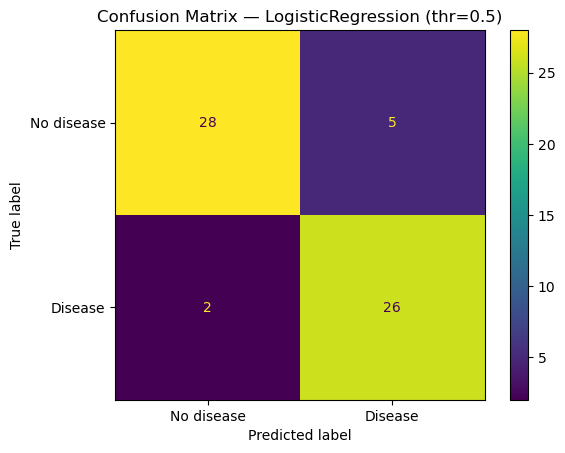

<Figure size 640x480 with 0 Axes>

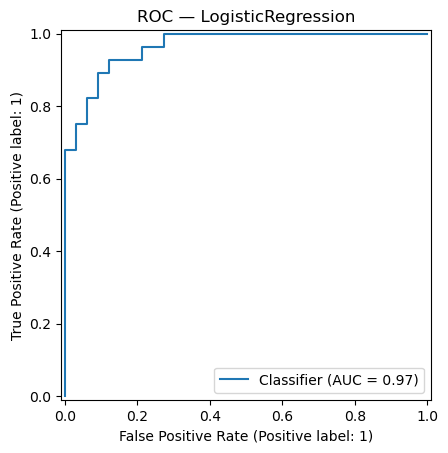

<Figure size 640x480 with 0 Axes>

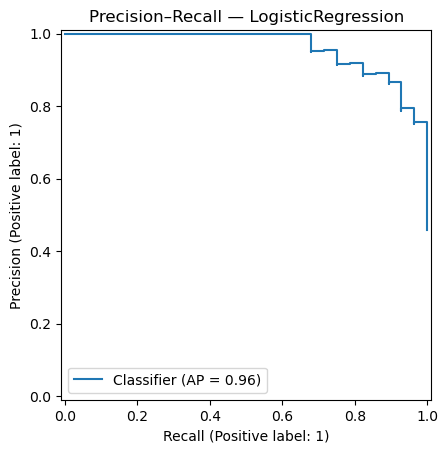

Threshold trade-off table:


,threshold,Accuracy,F1,Precision,Recall,FN,FP
0,0.3,0.836066,0.848485,0.736842,1.000000,0,10
1,0.4,0.852459,0.857143,0.771429,0.964286,1,8
2,0.5,0.885246,0.881356,0.838710,0.928571,2,5
3,0.6,0.901639,0.896552,0.866667,0.928571,2,4


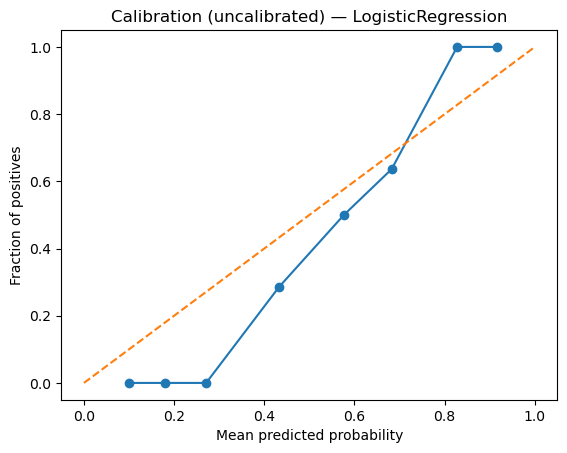

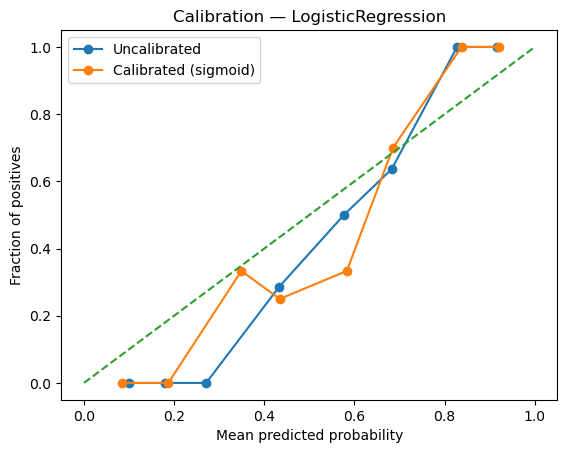

In [27]:
# 13) Fit final on full train + test evaluation
# -----------------------------
final_model.fit(X_train, y_train)
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred_05 = (y_proba >= 0.5).astype(int)

test_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_pred_05),
    "F1": f1_score(y_test, y_pred_05),
    "Precision": precision_score(y_test, y_pred_05),
    "Recall": recall_score(y_test, y_pred_05),
    "ROC_AUC": roc_auc_score(y_test, y_proba),
}])
print("Test metrics (thr=0.5):")
display(test_metrics)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_05)
plt.figure()
ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(values_format="d")
plt.title(f"Confusion Matrix — {best_model_name} (thr=0.5)")
plt.show()

# ROC / PR
plt.figure()
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title(f"ROC — {best_model_name}")
plt.show()

plt.figure()
PrecisionRecallDisplay.from_predictions(y_test, y_proba)
plt.title(f"Precision–Recall — {best_model_name}")
plt.show()

# Threshold trade-off
thresholds = [0.3, 0.4, 0.5, 0.6]
rows = []
for t in thresholds:
    yp = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    rows.append({
        "threshold": t,
        "Accuracy": accuracy_score(y_test, yp),
        "F1": f1_score(y_test, yp),
        "Precision": precision_score(y_test, yp),
        "Recall": recall_score(y_test, yp),
        "FN": fn,
        "FP": fp
    })
th_table = pd.DataFrame(rows)
print("Threshold trade-off table:")
display(th_table)

# Calibration (uncalibrated)
plt.figure()
pt, pp = calibration_curve(y_test, y_proba, n_bins=8, strategy="uniform")
plt.plot(pp, pt, marker="o")
plt.plot([0, 1], [0, 1], "--")
plt.title(f"Calibration (uncalibrated) — {best_model_name}")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.show()

# Optional calibration
try:
    calibrated = CalibratedClassifierCV(final_model, method="sigmoid", cv=5)
    calibrated.fit(X_train, y_train)
    y_proba_cal = calibrated.predict_proba(X_test)[:, 1]

    plt.figure()
    pt2, pp2 = calibration_curve(y_test, y_proba_cal, n_bins=8, strategy="uniform")
    plt.plot(pp, pt, marker="o", label="Uncalibrated")
    plt.plot(pp2, pt2, marker="o", label="Calibrated (sigmoid)")
    plt.plot([0, 1], [0, 1], "--")
    plt.title(f"Calibration — {best_model_name}")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Fraction of positives")
    plt.legend()
    plt.show()
except Exception as e:
    print("Calibration skipped:", e)

In [28]:
# 14) Diagnostic-stage grouping (for BA slide)
# -----------------------------
screening = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "chol_per_age", "bps_per_age"] if c in X.columns]
ecg_exercise = [c for c in ["restecg", "thalach", "oldpeak", "exang", "slope"] if c in X.columns]
imaging = [c for c in ["ca", "thal"] if c in X.columns]

stage_map = pd.DataFrame({
    "Stage": ["Screening", "ECG & Exercise", "Imaging"],
    "Features": [", ".join(screening), ", ".join(ecg_exercise), ", ".join(imaging)]
})
print("Diagnostic-stage feature grouping:")
display(stage_map)

Diagnostic-stage feature grouping:


,Stage,Features
0,Screening,"age, sex, cp, trestbps, chol, fbs, chol_per_ag..."
1,ECG & Exercise,"restecg, thalach, oldpeak, exang, slope"
2,Imaging,"ca, thal"


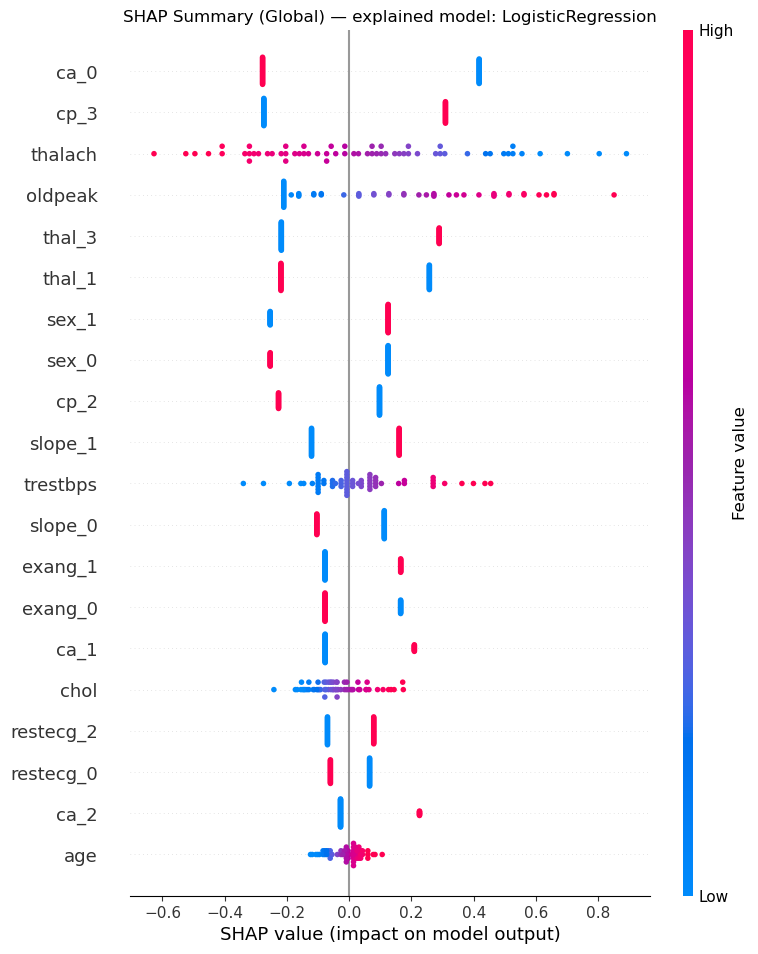

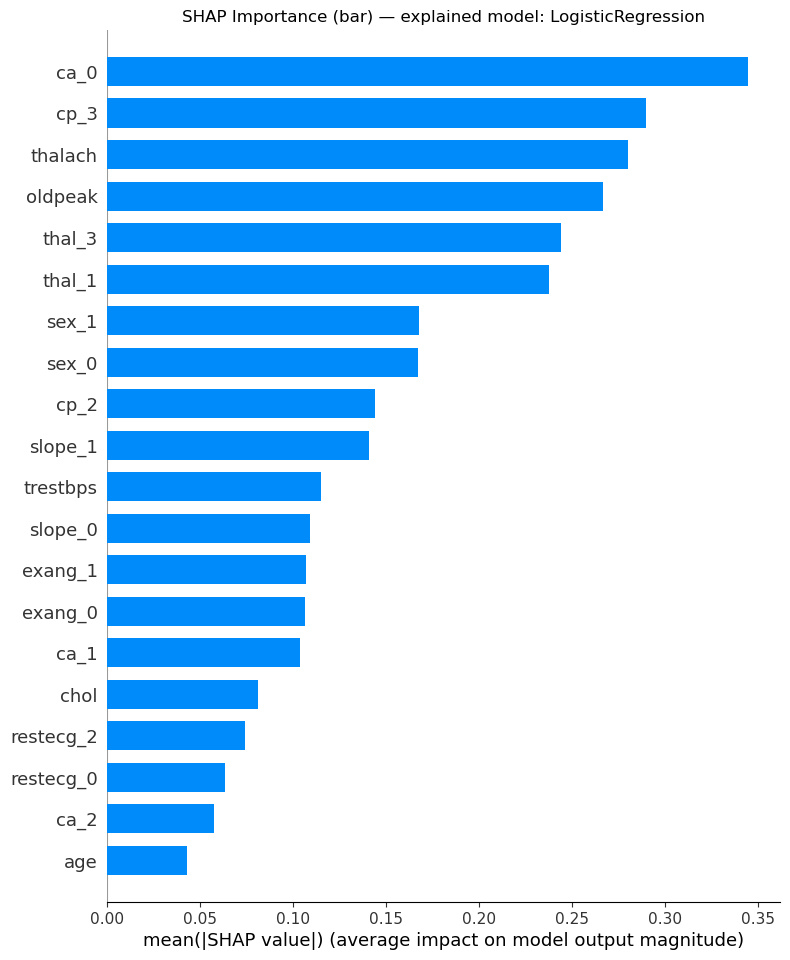

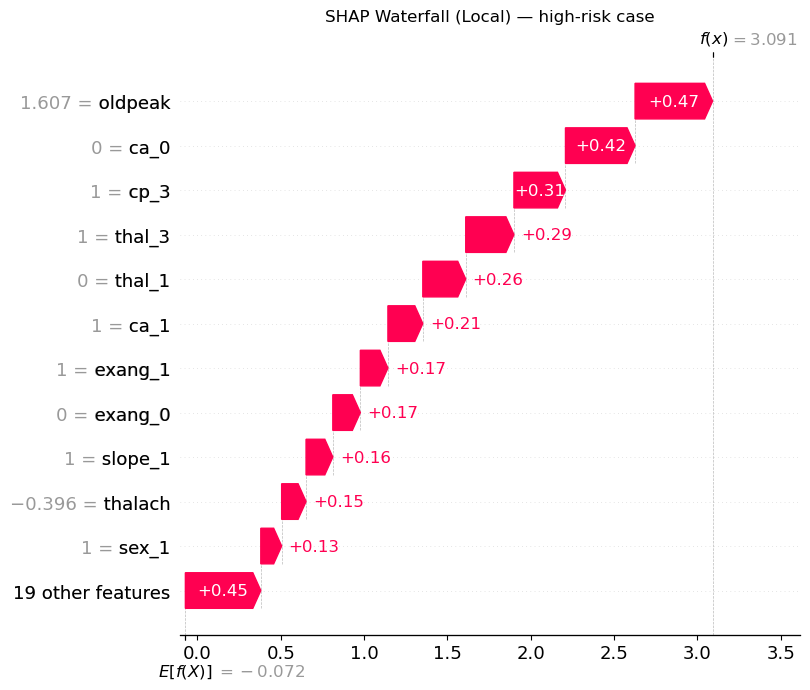

In [29]:
# 15) SHAP (global + local) + Decision-support prototype table
# -----------------------------
if SHAP_AVAILABLE:

    # ---- If VotingSoft wins: explain a SHAP-friendly base model for interpretability
    shap_model_name = best_model_name
    shap_model = final_model

    if best_model_name == "VotingSoft":
        base_only = {k: v for k, v in tuned.items() if k in ["LogisticRegression", "RandomForest", "XGBoost"]}
        base_repeated = cv_table(base_only, X_train, y_train, rskf)
        shap_model_name = base_repeated.iloc[0]["Model"]
        shap_model = tuned[shap_model_name]
        shap_model.fit(X_train, y_train)
        print(f"\VotingSoft selected for performance; SHAP explains base model: {shap_model_name}")
    else:
        # ensure fitted for SHAP
        shap_model.fit(X_train, y_train)

    pre = shap_model.named_steps["preprocess"]
    mdl = shap_model.named_steps["model"]
    Xtr = pre.transform(X_train)
    Xte = pre.transform(X_test)

    # Feature names after preprocessing
    def get_feature_names(ct: ColumnTransformer):
        names = []
        names += list(ct.transformers_[0][2])  # numeric
        ohe = ct.transformers_[1][1].named_steps["onehot"]
        cats = ct.transformers_[1][2]
        names += list(ohe.get_feature_names_out(cats))
        return names

    feat_names = get_feature_names(pre)

    # Compute SHAP values
    if shap_model_name in ["RandomForest", "XGBoost"]:
        explainer = shap.TreeExplainer(mdl)
        sv = explainer.shap_values(Xte)
        sv_use = sv[1] if isinstance(sv, list) else sv
        base_val = explainer.expected_value if np.isscalar(explainer.expected_value) else explainer.expected_value[1]
    else:
        explainer = shap.LinearExplainer(mdl, Xtr, feature_perturbation="interventional")
        sv_use = explainer.shap_values(Xte)
        base_val = explainer.expected_value

    # Global plots
    shap.summary_plot(sv_use, Xte, feature_names=feat_names, show=False)
    plt.title(f"SHAP Summary (Global) — explained model: {shap_model_name}")
    plt.show()

    shap.summary_plot(sv_use, Xte, feature_names=feat_names, plot_type="bar", show=False)
    plt.title(f"SHAP Importance (bar) — explained model: {shap_model_name}")
    plt.show()

    # Local plot: choose highest-risk case under FINAL model
    top_idx = int(np.argmax(y_proba))
    exp = shap.Explanation(
        values=sv_use[top_idx],
        base_values=base_val,
        data=Xte[top_idx],
        feature_names=feat_names
    )
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.title("SHAP Waterfall (Local) — high-risk case")
    plt.show()

In [30]:
# -----------------------------
    # Decision-support prototype (Top-N high risk patients)
    # -----------------------------
    # Map one-hot feature names back to base variable
def base_feature_name(fname: str) -> str:
    return fname.split("_")[0] if "_" in fname else fname

stage_dict = {}
for f in screening: stage_dict[f] = "Screening"
for f in ecg_exercise: stage_dict[f] = "ECG & Exercise"
for f in imaging: stage_dict[f] = "Imaging"

# Prototype action rules (NOT clinical guideline)
def action_recommendation(top_stages):
    if "Imaging" in top_stages:
        return "Prioritize advanced imaging / cardiology referral"
    if "ECG & Exercise" in top_stages:
        return "Prioritize stress test / ECG monitoring"
    return "Primary care follow-up (screening & risk-factor management)"

    # Choose Top-N by FINAL predicted risk
topN = 10
top_indices = np.argsort(-y_proba)[:topN]

rows = []
for i in top_indices:
    sv_i = sv_use[i]

        # Top 3 positive drivers (push risk up)
    top_pos = np.argsort(-sv_i)[:3]
    top_feats = [feat_names[j] for j in top_pos]
    top_base = [base_feature_name(f) for f in top_feats]
    top_stages = [stage_dict.get(b, "Other/Unknown") for b in top_base]

    rows.append({
        "Patient_ID (test row idx)": int(i),
        "Predicted_Risk (final)": float(y_proba[i]),
        "Top_Drivers (base vars)": ", ".join(top_base),
        "Driver_Stages": ", ".join(top_stages),
        "Suggested_Action (prototype)": action_recommendation(top_stages)
    })

decision_support_table = pd.DataFrame(rows)
print("Decision-support prototype table (Top high-risk patients):")
display(decision_support_table)

Decision-support prototype table (Top high-risk patients):


,Patient_ID (test row idx),Predicted_Risk (final),Top_Drivers (base vars),Driver_Stages,Suggested_Action (prototype)
0,51,0.956522,"oldpeak, ca, cp","ECG & Exercise, Imaging, Screening",Prioritize advanced imaging / cardiology referral
1,41,0.947504,"ca, oldpeak, cp","Imaging, ECG & Exercise, Screening",Prioritize advanced imaging / cardiology referral
2,19,0.929579,"thalach, ca, cp","ECG & Exercise, Imaging, Screening",Prioritize advanced imaging / cardiology referral
3,42,0.926602,"oldpeak, thalach, ca","ECG & Exercise, ECG & Exercise, Imaging",Prioritize advanced imaging / cardiology referral
4,15,0.924571,"thalach, ca, cp","ECG & Exercise, Imaging, Screening",Prioritize advanced imaging / cardiology referral
5,29,0.922121,"oldpeak, ca, thalach","ECG & Exercise, Imaging, ECG & Exercise",Prioritize advanced imaging / cardiology referral
6,55,0.921355,"ca, cp, thal","Imaging, Screening, Imaging",Prioritize advanced imaging / cardiology referral
7,48,0.916453,"ca, cp, thal","Imaging, Screening, Imaging",Prioritize advanced imaging / cardiology referral
8,14,0.898415,"thalach, ca, cp","ECG & Exercise, Imaging, Screening",Prioritize advanced imaging / cardiology referral
9,10,0.897941,"thalach, ca, thal","ECG & Exercise, Imaging, Imaging",Prioritize advanced imaging / cardiology referral


In [31]:
# 16) Final summary for slides/report
# -----------------------------
print("\n==================== FINAL SUMMARY ====================")
print("Final model (by repeated CV AUC):", best_model_name)
print("\nTuned CV (5-fold):")
display(cv_tuned_5fold)
print("\nRepeated CV (5x5):")
display(cv_tuned_repeated)
print("\nTest metrics (thr=0.5):")
display(test_metrics)
print("\nThreshold trade-off:")
display(th_table)
print("=======================================================")



==================== FINAL SUMMARY ====================
Final model (by repeated CV AUC): LogisticRegression

Tuned CV (5-fold):


,Model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std
0,LogisticRegression,0.903114,0.017300,0.813175,0.023009,0.823221,0.043486,0.809881,0.067996,0.830442,0.016761
1,RandomForest,0.899906,0.023297,0.779255,0.034943,0.794466,0.045776,0.773518,0.087499,0.801446,0.022782
3,VotingSoft,0.895929,0.018541,0.788176,0.051722,0.802529,0.056096,0.782609,0.093802,0.809609,0.041339
2,XGBoost,0.871917,0.018323,0.771150,0.046637,0.767621,0.048254,0.783004,0.089265,0.789286,0.035573



Repeated CV (5x5):


,Model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,accuracy_mean,accuracy_std
0,LogisticRegression,0.897080,0.040028,0.801029,0.056923,0.820217,0.076453,0.788617,0.074210,0.820544,0.052047
1,RandomForest,0.893195,0.039298,0.783627,0.053153,0.806032,0.066111,0.768775,0.080031,0.806548,0.045445
3,VotingSoft,0.892095,0.040185,0.782839,0.059114,0.797153,0.076490,0.776047,0.082099,0.803197,0.054099
2,XGBoost,0.872247,0.044970,0.763505,0.055388,0.767420,0.073935,0.767115,0.080457,0.782670,0.051021



Test metrics (thr=0.5):


,Model,Accuracy,F1,Precision,Recall,ROC_AUC
0,LogisticRegression,0.885246,0.881356,0.83871,0.928571,0.965368



Threshold trade-off:


,threshold,Accuracy,F1,Precision,Recall,FN,FP
0,0.3,0.836066,0.848485,0.736842,1.000000,0,10
1,0.4,0.852459,0.857143,0.771429,0.964286,1,8
2,0.5,0.885246,0.881356,0.838710,0.928571,2,5
3,0.6,0.901639,0.896552,0.866667,0.928571,2,4
